# VietOnlineNews · Tải và khảo sát dữ liệu

Chạy **Run All**. Nếu thiếu thư viện, chạy trong một cell: `%pip install pandas matplotlib huggingface_hub`.

Notebook tải 3 CSV raw (~1,26 GB) vào `data/`, giữ nguyên dữ liệu và hiển thị kết quả tại đây.

[Dataset](https://huggingface.co/datasets/VLUS06/VietOnlineNews) · [Hướng dẫn tải](https://huggingface.co/docs/huggingface_hub/guides/download)

**Xem mẫu → tổng quan → metadata → chất lượng → độ phủ thời gian.** `category` là chủ đề, không phải sự kiện.

In [1]:
from pathlib import Path
from urllib.parse import urlsplit
import hashlib
import re
import unicodedata

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from huggingface_hub import HfApi, hf_hub_download

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/01_vietonlinenews_overview.ipynb").is_file())
RAW_DIR = ROOT / "data"
RAW_DIR.mkdir(exist_ok=True)
REPO_ID = "VLUS06/VietOnlineNews"
REVISION = "bd8d2a865c8981d34cb9d85f69f62bda7c40b520"
LOCAL_TZ = "Asia/Ho_Chi_Minh"
FILES = {"Tuổi Trẻ": "merged_data_tuoitre.csv",
         "Thanh Niên": "merged_data_thanhnien.csv",
         "VietnamNet": "merged_data_vietnamnet.csv"}
CSV_OPTIONS = dict(dtype="string", keep_default_na=False, encoding="utf-8-sig",
                   on_bad_lines="error", skip_blank_lines=False)
pd.set_option("display.max_colwidth", 85)
print("Revision:", REVISION)

Revision: bd8d2a865c8981d34cb9d85f69f62bda7c40b520


## 1. Tải dữ liệu

Dùng lại file đã tải, kiểm tra kích thước và checksum với phiên bản cố định ở trên. Cần internet để đối chiếu upstream. Không tạo thêm file báo cáo hoặc cấu hình.

In [2]:
import shutil
from tempfile import TemporaryDirectory

info = HfApi().dataset_info(REPO_ID, revision=REVISION, files_metadata=True)
remote = {f.rfilename: f for f in info.siblings}
display(pd.DataFrame([{"file": name, "MB": round(remote[f"raw/{name}"].size / 1e6, 2)}
                      for name in FILES.values()]))

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

for name in FILES.values():
    path = RAW_DIR / name
    upstream = remote[f"raw/{name}"]
    if not path.exists():
        # Cache tải nằm trong thư mục tạm, không để lại file phụ trong project.
        with TemporaryDirectory(prefix="vietonlinenews-") as temp:
            downloaded = hf_hub_download(repo_id=REPO_ID, repo_type="dataset",
                revision=REVISION, filename=f"raw/{name}", local_dir=temp)
            downloaded = Path(downloaded)
            if downloaded.stat().st_size != upstream.size or sha256_file(downloaded) != upstream.lfs.sha256:
                raise ValueError(f"File tải về không khớp upstream: {name}")
            shutil.move(str(downloaded), path)
    if path.stat().st_size != upstream.size or sha256_file(path) != upstream.lfs.sha256:
        raise ValueError(f"File không khớp upstream: {name}")
print("Đã kiểm tra 3 CSV:", RAW_DIR)

,file,MB
0,merged_data_tuoitre.csv,280.73
1,merged_data_thanhnien.csv,462.76
2,merged_data_vietnamnet.csv,515.20


Đã kiểm tra 3 CSV: /Users/tun/Documents/2026.1/Intro2 Data Science/Vietnamese-News-Trend-Analysis-Prediction/data


## 2. Xem schema và bài mẫu

Preview là 3 bài đầu mỗi nguồn. Các thống kê ở phần sau được tính trên **toàn bộ dữ liệu**.

In [3]:
previews, schemas = [], []
for source, name in FILES.items():
    sample = pd.read_csv(RAW_DIR / name, nrows=3, **CSV_OPTIONS)
    schemas.append({"source": source, "columns": ", ".join(sample.columns)})
    previews.append(sample.assign(source_file=source))
preview = pd.concat(previews, ignore_index=True)
display(pd.DataFrame(schemas))
display(preview[["source_file", "title", "description", "public_date", "url"]])

,source,columns
0,Tuổi Trẻ,"category, sub_topic, title, description, content, public_date, author, source, ur..."
1,Thanh Niên,"category, sub_topic, title, description, content, public_date, author, source, ur..."
2,VietnamNet,"category, sub_topic, title, description, content, public_date, author, source, ur..."


,source_file,title,description,public_date,url
0,Tuổi Trẻ,"Hoàn thiện chính sách đặc thù về đặc khu Vân Đồn, Vân Phong, Phú Quốc để trình Bộ...","Phó thủ tướng yêu cầu hoàn thiện đề án tổng thể về các cơ chế, chính sách đặc thù...",2025-12-30T19:31:59+07:00,https://tuoitre.vn/hoan-thien-chinh-sach-dac-thu-ve-dac-khu-van-don-van-phong-phu...
1,Tuổi Trẻ,"Các luật mới từ ngày 1-1 tác động đến đầu tư, đất đai, năng lượng","Từ ngày 1-1-2026, nhiều luật, nhóm chính sách quan trọng liên quan trực tiếp, có ...",2025-12-30T18:43:19+07:00,https://tuoitre.vn/cac-luat-moi-tu-ngay-1-1-tac-dong-den-dau-tu-dat-dai-nang-luon...
2,Tuổi Trẻ,Thanh tra Chính phủ kết luận gì về dự án Golden Hills Đà Nẵng của Trung Nam?,"Thanh tra Chính phủ vừa có kết luận thanh tra các dự án có khó khăn, vướng mắc tạ...",2025-12-26T19:23:09+07:00,https://tuoitre.vn/thanh-tra-chinh-phu-ket-luan-gi-ve-du-an-golden-hills-da-nang-...
3,Thanh Niên,Coinbase lộ dữ liệu 70.000 người dùng Mỹ: KYC rủi ro nhưng vì sao không thể bỏ?,"Sau vụ sàn giao dịch Coinbase làm lộ dữ liệu của 70.000 người dùng Mỹ, nhiều ngườ...",2025-06-06T10:05:00+07:00,https://thanhnien.vn/coinbase-lo-du-lieu-70000-nguoi-dung-my-kyc-rui-ro-nhung-vi-...
4,Thanh Niên,Giá Bitcoin được dự đoán lên 1 triệu USD,"Tỉ phú Changpeng Zhao (CZ), nhà sáng lập Binance dự đoán giá Bitcoin có thể đạt 5...",2025-05-10T11:36:00+07:00,https://thanhnien.vn/gia-bitcoin-duoc-du-doan-len-1-trieu-usd-185250508184258394.htm
5,Thanh Niên,Shark Bình tâm tư điều gì về 'vết nhơ' AntEx?,"Bốn năm trước, ông Nguyễn Hòa Bình (Shark Bình) liên tục quảng bá cho dự án AntEx...",2025-09-27T08:43:00+07:00,https://thanhnien.vn/shark-binh-tam-tu-dieu-gi-ve-vet-nho-antex-18525092708090648...
6,VietnamNet,Cảnh hoang phế tại dự án nhà ở xã hội 700 tỷ đồng ở cửa ngõ Đà Nẵng,"Được cấp phép từ năm 2008, quy hoạch hàng nghìn căn hộ cho người thu nhập thấp, n...",2025-12-31T05:45:00.000 +07:00,https://vietnamnet.vn/canh-hoang-phe-tai-du-an-nha-o-xa-hoi-700-ty-dong-o-cua-ngo...
7,VietnamNet,Green Skyline - ‘Chân trời xanh’ mới của bất động sản Đông Bắc TP.HCM,Thị trường BĐS Việt Nam bước vào chu kỳ tái cấu trúc sâu. Sự kiện ra quân dự án G...,2025-12-30T14:30:00.000 +07:00,https://vietnamnet.vn/green-skyline-chan-troi-xanh-moi-cua-bat-dong-san-dong-bac-...
8,VietnamNet,Hơn 600 khách mời dự sự kiện giới thiệu Charmora City tại Hà Nội,"Ngày 27/12/2025, tại Ascott Tây Hồ (Hà Nội), Sun Property tổ chức sự kiện giới th...",2025-12-30T09:55:00.000 +07:00,https://vietnamnet.vn/hon-600-khach-moi-du-su-kien-gioi-thieu-charmora-city-tai-h...


In [4]:
# Đổi số từ 0 đến 8 để xem một bài mẫu.
article = preview.iloc[0]
print(article["title"])
print(article["public_date"], "|", article["source"])
print(str(article["content"])[:1500])

Hoàn thiện chính sách đặc thù về đặc khu Vân Đồn, Vân Phong, Phú Quốc để trình Bộ Chính trị
2025-12-30T19:31:59+07:00 | Tuổi Trẻ
Đặc khu Vân Đồn - Ảnh: NGUYỄN TRIỀU
Văn phòng Chính phủ vừa có thông báo kết luận của Phó thủ tướng thường trực Chính phủ Nguyễn Hòa Bình tại buổi làm việc với lãnh đạotỉnh Quảng Ninhđã nêu ra yêu cầu trên.
Theo đó, Phó thủ tướng thường trực yêu cầu Quảng Ninh tiếp tục đi đầu trong cải cách hành chính, lấy mức độ hài lòng của người dân và doanh nghiệp làm thước đo, đẩy mạnh đầu tư hạ tầng số, đáp ứng tốt hơn nữa việc giải quyết thủ tục hành chính cho nhân dân.
Tỉnh cần nâng cao năng lực quản trị xã hội, quản trị kinh tế của chính quyền cấp xã. Xây dựng chính quyền xã phải đạt hai yêu cầu: phục vụ nhân dân tốt hơn và phát triển kinh tế xã hội, quản trị địa bàn dân cư tốt hơn.
Trong đó cần tập trung giải quyết các cơ sở nhà, đất dôi dư, bảo đảm hiệu quả, không thất thoát, lãng phí; chủ động, sáng tạo thực hiện các nhiệm vụ, quyền hạn được phân cấp, phân quyền, 

## 3. Quét toàn bộ dữ liệu

Đọc từng chunk 10.000 dòng; chỉ giữ metadata và đặc trưng kiểm tra trong RAM. Ô trống và placeholder được đếm riêng. Ngày thiếu offset được giả định giờ Việt Nam và gắn cờ. Hash chỉ giúp tìm nội dung lặp; chưa xóa bài.

In [5]:
FIELDS = ["title", "description", "content", "public_date", "source", "url",
          "category", "author", "sub_topic", "tag"]
SOURCE_ALIASES = {
    "tuổi trẻ": "Tuổi Trẻ", "tuoitre": "Tuổi Trẻ",
    "báo thanh niên": "Thanh Niên", "thanh niên": "Thanh Niên",
    "báo thanh niên - kết nối": "Thanh Niên",
    "vietnamnet": "VietnamNet", "vietnamnet.vn": "VietnamNet",
}
DOMAINS = {"Tuổi Trẻ": "tuoitre.vn", "Thanh Niên": "thanhnien.vn", "VietnamNet": "vietnamnet.vn"}
PLACEHOLDERS = {"null", "none", "nan", "n/a", "na", "undefined", "<na>"}


def blank_mask(series):
    return series.isna() | series.fillna("").str.strip().eq("")

def normalize_text(text):
    return unicodedata.normalize("NFC", " ".join(text.split()))

def text_hash(text):
    normalized = normalize_text(text)
    return hashlib.sha256(normalized.encode("utf-8")).hexdigest() if normalized else pd.NA

def url_check(value, expected_source):
    if not value.strip():
        return "missing"
    try:
        parsed = urlsplit(value.strip())
        host = (parsed.hostname or "").lower()
        if parsed.scheme.lower() not in {"http", "https"} or not host or parsed.username or re.search(r"\s", value):
            return "invalid"
        # Accessing .port also detects invalid port syntax.
        _ = parsed.port
        expected = DOMAINS[expected_source]
        return "ok" if host == expected or host.endswith("." + expected) else "unexpected_host"
    except ValueError:
        return "invalid"

def parse_public_dates(series):
    text = series.fillna("").str.strip()
    has_offset = text.str.contains(r"(?:Z|[+-]\d{2}:?\d{2})$", flags=re.I, regex=True)
    naive_iso = text.str.match(r"^\d{4}-\d{2}-\d{2}(?:[ T].*)?$") & ~has_offset
    parsed = pd.Series(pd.NaT, index=series.index, dtype="datetime64[ns, UTC]")
    if has_offset.any():
        parsed.loc[has_offset] = pd.to_datetime(text[has_offset], errors="coerce", format="mixed", utc=True)
    if naive_iso.any():
        naive = pd.to_datetime(text[naive_iso], errors="coerce", format="ISO8601")
        parsed.loc[naive_iso] = naive.dt.tz_localize(LOCAL_TZ).dt.tz_convert("UTC")
    return parsed.dt.tz_convert(LOCAL_TZ), naive_iso & parsed.notna()

In [6]:
parts, missing_rows, source_labels = [], [], []
for source, name in FILES.items():
    print("Đang đọc:", source, flush=True)
    total = 0
    missing = {field: 0 for field in FIELDS}
    placeholders = {field: 0 for field in FIELDS}
    header = pd.read_csv(RAW_DIR / name, nrows=0, **CSV_OPTIONS).columns
    for chunk in pd.read_csv(RAW_DIR / name, chunksize=10_000, **CSV_OPTIONS):
        chunk = chunk.reset_index(drop=True).reindex(columns=FIELDS).fillna("")
        for field in FIELDS:
            missing[field] += int(blank_mask(chunk[field]).sum())
            placeholders[field] += int(chunk[field].str.strip().str.lower().isin(PLACEHOLDERS).sum())
        published, assumed = parse_public_dates(chunk["public_date"])
        urls = chunk["url"].str.strip()
        normalized_source = chunk["source"].str.strip().str.lower().map(SOURCE_ALIASES)
        parts.append(pd.DataFrame({
            "source": source, "category": chunk["category"], "url": urls,
            "published_at": published, "timezone_assumed": assumed,
            "date_missing": blank_mask(chunk["public_date"]),
            "source_mismatch": ~normalized_source.eq(source).fillna(False),
            "url_status": urls.map(lambda value: url_check(value, source)),
            "title_chars": chunk["title"].str.len(),
            "content_chars": chunk["content"].str.len(),
            "content_hash": chunk["content"].map(text_hash),
        }))
        source_labels.append(chunk["source"].value_counts().rename_axis("source_raw").reset_index(name="rows").assign(source=source))
        total += len(chunk)
    for field in FIELDS:
        missing_rows.append({"source": source, "field": field, "column_present": field in header,
                             "missing": missing[field], "missing_pct": round(100 * missing[field] / total, 3),
                             "placeholder": placeholders[field]})
articles = pd.concat(parts, ignore_index=True)
del parts
completeness = pd.DataFrame(missing_rows)
articles["date"] = articles["published_at"].dt.tz_localize(None).dt.normalize()
print(f"Đã đọc {len(articles):,} dòng. Không sửa file raw.")

Đang đọc: Tuổi Trẻ


Đang đọc: Thanh Niên


Đang đọc: VietnamNet


Đã đọc 273,058 dòng. Không sửa file raw.


## 4. Dataset Overview

Số dòng raw có thể khác **265.729 bài processed** ghi trên dataset card. Chủ đề raw chưa được chuẩn hóa.

In [7]:
overview = articles.groupby("source").agg(
    rows=("source", "size"), first_date=("published_at", "min"),
    last_date=("published_at", "max"), categories=("category", "nunique"))
display(overview)
display(pd.concat(source_labels).groupby(["source", "source_raw"], as_index=False)["rows"].sum())
display(articles.groupby("source")[["title_chars", "content_chars"]].quantile([.01, .5, .99]).round())
print("10 chủ đề raw có nhiều bản ghi nhất:")
display(articles["category"].value_counts().head(10).to_frame("rows"))

,rows,first_date,last_date,categories
source,,,,
Thanh Niên,96017,2023-01-01 00:46:38+07:00,2025-12-31 23:21:00+07:00,11
Tuổi Trẻ,53010,2023-01-01 07:51:34+07:00,2025-12-31 22:44:30+07:00,12
VietnamNet,124031,2023-01-01 05:20:00+07:00,2025-12-31 23:42:02+07:00,13


,source,source_raw,rows
0,Thanh Niên,Báo Thanh Niên,96008
1,Thanh Niên,Báo Thanh Niên - Kết nối,9
2,Tuổi Trẻ,Tuổi Trẻ,53010
3,VietnamNet,Vietnamnet,124031


title_chars  content_chars
source                                     
Thanh Niên 0.01         27.0          963.0
           0.50         63.0         2765.0
           0.99         92.0        10678.0
Tuổi Trẻ   0.01         24.0          923.0
           0.50         64.0         3299.0
           0.99         98.0         8497.0
VietnamNet 0.01         30.0            0.0
           0.50         64.0         2472.0
           0.99         80.0         7486.0

10 chủ đề raw có nhiều bản ghi nhất:


,rows
category,
Giải trí,28828
Thể thao,27447
Kinh doanh,23174
Thời sự,16110
giai tri,14645
Xe,13652
Sức khỏe,13272
Giáo dục,13183
cong nghe,12796


## 5. Metadata Completeness

Xem tỷ lệ thiếu theo nguồn trước, rồi các trường có vấn đề. Raw không có `article_id` và `collected_at`; tạo ID ở bước chuẩn hóa, không dùng ngày tải thay ngày crawl gốc.

In [8]:
display(completeness.pivot(index="field", columns="source", values="missing_pct"))
display(completeness.loc[(completeness["missing"] > 0) | (completeness["placeholder"] > 0)
                         | ~completeness["column_present"]])

source,Thanh Niên,Tuổi Trẻ,VietnamNet
field,,,
author,0.078,2.592,20.681
category,0.000,0.000,0.000
content,0.306,0.025,1.451
description,0.015,0.272,0.000
public_date,0.000,0.000,0.000
source,0.000,0.000,0.000
sub_topic,0.000,0.000,0.000
tag,0.087,0.000,0.001
title,0.001,0.000,0.001


,source,field,column_present,missing,missing_pct,placeholder
1,Tuổi Trẻ,description,True,144,0.272,0
2,Tuổi Trẻ,content,True,13,0.025,0
7,Tuổi Trẻ,author,True,1374,2.592,0
10,Thanh Niên,title,True,1,0.001,0
11,Thanh Niên,description,True,14,0.015,0
12,Thanh Niên,content,True,294,0.306,0
17,Thanh Niên,author,True,75,0.078,0
19,Thanh Niên,tag,True,84,0.087,0
20,VietnamNet,title,True,1,0.001,0
22,VietnamNet,content,True,1800,1.451,0


## 6. Ngày, URL và nội dung lặp

URL chỉ được kiểm tra cấu trúc và hostname, chưa kiểm tra truy cập. Nội dung giống nhau là ứng viên để xem lại, không tự loại bỏ. Ngưỡng 200 ký tự chỉ là cờ khảo sát.

In [9]:
outside = articles["date"].notna() & ~articles["date"].between("2023-01-01", "2025-12-31")
flags = pd.DataFrame({
    "source": articles["source"],
    "date_missing": articles["date_missing"],
    "date_invalid": ~articles["date_missing"] & articles["published_at"].isna(),
    "timezone_assumed": articles["timezone_assumed"],
    "outside_2023_2025": outside,
    "source_mismatch": articles["source_mismatch"],
    "url_invalid_or_missing": articles["url_status"].ne("ok"),
    "content_short_1_to_199_chars": articles["content_chars"].between(1, 199),
})
display(flags.groupby("source").sum())
valid_urls = articles.loc[articles["url"].ne("")]
valid_content = articles.dropna(subset=["content_hash"])
content_sizes = valid_content.groupby("content_hash").size()
display(pd.DataFrame({"check": ["URL lặp trong cùng nguồn (dòng vượt dòng đầu)",
                              "Nhóm nội dung lặp", "Nội dung lặp (dòng vượt dòng đầu)"],
                      "count": [int(valid_urls.duplicated(["source", "url"]).sum()),
                                int(content_sizes.gt(1).sum()), int((content_sizes - 1).sum())]}))

,date_missing,date_invalid,timezone_assumed,outside_2023_2025,source_mismatch,url_invalid_or_missing,content_short_1_to_199_chars
source,,,,,,,
Thanh Niên,0,0,6,0,0,0,2
Tuổi Trẻ,0,0,0,0,0,0,42
VietnamNet,0,0,0,0,0,0,4259


,check,count
0,URL lặp trong cùng nguồn (dòng vượt dòng đầu),0
1,Nhóm nội dung lặp,393
2,Nội dung lặp (dòng vượt dòng đầu),2014


## 7. Độ phủ theo ngày và nguồn

Có bài mỗi ngày không có nghĩa đã thu thập đủ bài. Ngày 0 bản ghi cần xác minh trước khi coi là ngày không có tin. Đếm theo ngày đăng giờ Việt Nam; dòng lỗi ngày không nằm trong đồ thị.

,days_expected,days_with_records,zero_record_days,median_rows_per_day
source,,,,
Tuổi Trẻ,1096,1096,0,44.0
Thanh Niên,1096,1096,0,85.0
VietnamNet,1096,1096,0,113.0


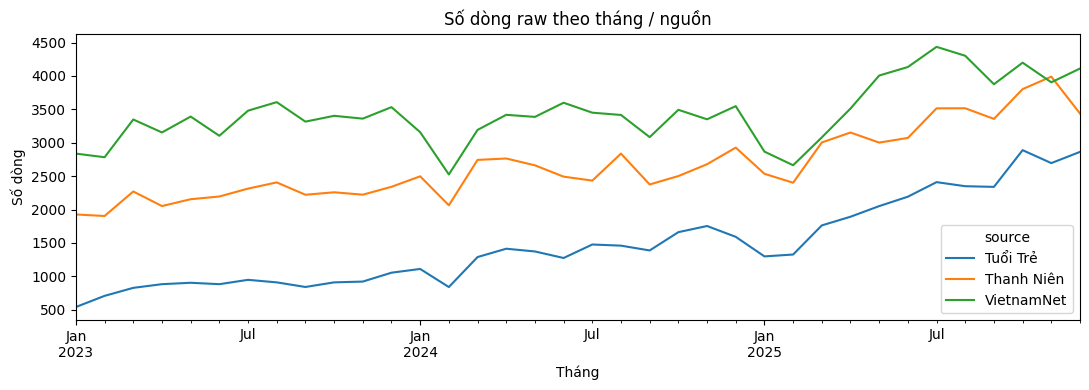

In [10]:
grid = pd.date_range("2023-01-01", "2025-12-31", freq="D")
daily = (articles.groupby(["date", "source"]).size().unstack(fill_value=0)
         .reindex(index=grid, columns=list(FILES), fill_value=0).fillna(0).astype(int))
display(pd.DataFrame({"days_expected": len(grid), "days_with_records": daily.gt(0).sum(),
                      "zero_record_days": daily.eq(0).sum(),
                      "median_rows_per_day": daily.median()}))
ax = daily.resample("MS").sum().plot(figsize=(11, 4), title="Số dòng raw theo tháng / nguồn")
ax.set_xlabel("Tháng")
ax.set_ylabel("Số dòng")
plt.tight_layout()
plt.show()

**Tiếp theo:** chuẩn hóa schema/ngày/nguồn; thống nhất cách xử lý thiếu text và bản ghi trùng; kiểm tra độ phủ trước khi tạo chuỗi thời gian. Raw được giữ nguyên, dữ liệu đã xử lý sẽ lưu riêng khi cần.